In [1]:
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_google_genai import GoogleGenerativeAIEmbeddings
from dotenv import load_dotenv
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_core.tools import tool
from langgraph.graph import StateGraph, START
from typing import Annotated, TypedDict
from langgraph.graph.message import add_messages
from langchain_core.messages import HumanMessage, BaseMessage
from langgraph.prebuilt import ToolNode, tools_condition

C:\Users\farsi\AppData\Local\Temp\ipykernel_17440\1860997399.py:5: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader


In [2]:
load_dotenv()

True

In [3]:
llm = ChatOpenAI(model="gpt-4o-mini") 

In [4]:
# llm = ChatGoogleGenerativeAI(
#     model="gemini-2.5-flash",
#     temperature=0.7
# )

In [5]:
loader = PyPDFLoader("template.pdf")
docs = loader.load()

In [6]:
docs

[Document(metadata={'producer': 'pdfTeX-1.40.28', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-09-11T22:05:57+01:00', 'author': 'Francisco Antunes Ribeiro e Silva', 'title': 'Probabilistic Error Functions for Generative AI Models', 'subject': 'Some thoughts on the Life, the Universe, and Everything Else', 'keywords': '', 'moddate': '2025-09-11T22:05:57+01:00', 'trapped': '/False', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.28 (TeX Live 2025) kpathsea version 6.4.1', 'source': 'template.pdf', 'total_pages': 185, 'page': 0, 'page_label': ''}, page_content='FRANCISCO ANTUNES RIBEIRO E SIL V A\nMaster/BSc in Computer Science\nPROBABILISTIC ERROR FUNCTIONS FOR\nGENERA TIVE AI MODELS\nSOME THOUGHTS ON THE LIFE, THE UNIVERSE,\nAND EVERYTHING ELSE\nMASTER IN STUDY PROGRAM NAME\nSPECIALIZA TION IN SPECIALIZA TION NAME\nNOVA University Lisbon\nDraft:September 11, 2025\nDEPARTMENT OF\nCOMPUTER SCIENCE'),
 Document(metadata={'producer': 'pdfTeX-1.40.28', 'creator':

In [7]:
len(docs)

185

In [8]:
splitter = RecursiveCharacterTextSplitter(chunk_size=1000, chunk_overlap=200)
chunks = splitter.split_documents(docs)

In [9]:
len(chunks)

695

In [10]:
embeddings = OpenAIEmbeddings(model='text-embedding-3-small')
vector_store = FAISS.from_documents(chunks, embeddings)

In [11]:
# embeddings = GoogleGenerativeAIEmbeddings(
#     model="gemini-embedding-001"
# )
# vector_store = FAISS.from_documents(chunks, embeddings)
vector_store.save_local("faiss_index")

In [12]:
vector_store

In [13]:
retriever = vector_store.as_retriever(search_type='similarity', search_kwargs={'k':4})

In [14]:
ans = retriever.invoke("What is Bayesian Inference?")
ans

[Document(id='4d0a0b21-4c73-4e65-bb28-2c5d63875635', metadata={'producer': 'pdfTeX-1.40.28', 'creator': 'LaTeX with hyperref', 'creationdate': '2025-09-11T22:05:57+01:00', 'author': 'Francisco Antunes Ribeiro e Silva', 'title': 'Probabilistic Error Functions for Generative AI Models', 'subject': 'Some thoughts on the Life, the Universe, and Everything Else', 'keywords': '', 'moddate': '2025-09-11T22:05:57+01:00', 'trapped': '/False', 'ptex.fullbanner': 'This is pdfTeX, Version 3.141592653-2.6-1.40.28 (TeX Live 2025) kpathsea version 6.4.1', 'source': 'template.pdf', 'total_pages': 185, 'page': 13, 'page_label': '6'}, page_content='Within the Bayesian framework [0], several key components are fundamental to the\nanalysis.\nThepriorencapsulates the initial beliefs about the parameters before any data is\nobserved [0]. The choice of prior can significantly impact inference, especially with\nlimiteddata. Commonexamplesincludeinformativepriors(basedondomainknowledge\norpreviousstudies[0]),n

In [15]:
@tool
def rag_tool(query: str) -> str:
    """
    Retrieve relevant information from the PDF document.

    Use this tool when the user asks factual or conceptual questions
    that may be answered using the stored PDF documents.

    Args:
        query: The question or search query used to retrieve PDF content.
    """

    documents = retriever.invoke(query)

    if not documents:
        return "No relevant information was found in the PDF."

    formatted_documents = []

    for index, document in enumerate(documents, start=1):
        source = document.metadata.get("source", "Unknown source")
        page = document.metadata.get("page", "Unknown page")

        formatted_documents.append(
            f"Document {index}\n"
            f"Source: {source}\n"
            f"Page: {page}\n"
            f"Content: {document.page_content}"
        )

    return "\n\n".join(formatted_documents)

In [16]:
tools = [rag_tool]
llm_with_tools = llm.bind_tools(tools)

In [17]:
class ChatState(TypedDict):
    messages: Annotated[list[BaseMessage], add_messages]

In [18]:
# graph nodes
def chat_node(state: ChatState):
    """LLM node that may answer or request a tool call."""
    messages = state['messages']
    response = llm_with_tools.invoke(messages)
    return {"messages": [response]}

tool_node = ToolNode(tools)  # Executes tool calls

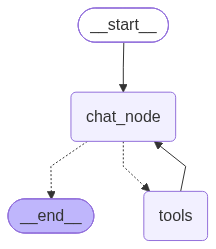

In [19]:
# graph structure
graph = StateGraph(ChatState)
graph.add_node("chat_node", chat_node)
graph.add_node("tools", tool_node)
graph.add_edge(START, "chat_node")

# If the LLM asked for a tool, go to ToolNode; else finish
graph.add_conditional_edges("chat_node", tools_condition)

graph.add_edge("tools", "chat_node")  
chatbot = graph.compile()

chatbot

In [20]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Hello")]})

print(result["messages"][-1].content)

Hello! How can I assist you today?


In [23]:
# Regular chat
result = chatbot.invoke({"messages": [HumanMessage(content="Using the pdf notes, explain about Bayesian Inference techniques in a concise way")]})

print(result["messages"][-1].content)

Bayesian Inference is a statistical technique that allows for updating beliefs about uncertain parameters as new data becomes available. It is grounded in Bayes' theorem, which relates the prior beliefs (prior distribution) to the likelihood of the observed data, resulting in a posterior distribution that reflects updated beliefs.

### Key Components:
1. **Prior Distribution**: This encapsulates initial beliefs about the parameters before observing any data. The choice of prior can influence the inference, particularly in cases of limited data. There are informative priors (based on previous knowledge) and non-informative priors (minimally influential).

2. **Likelihood**: This represents the probability of observing the data given the parameters. It is crucial for updating the prior beliefs to form the posterior distribution.

3. **Posterior Distribution**: This is the updated belief about the parameters after considering the observed data. It combines the prior distribution and the l

In [27]:
print(result["messages"][-1].content)

Bayesian Inference is a statistical technique that allows for updating beliefs about uncertain parameters as new data becomes available. It is grounded in Bayes' theorem, which relates the prior beliefs (prior distribution) to the likelihood of the observed data, resulting in a posterior distribution that reflects updated beliefs.

### Key Components:
1. **Prior Distribution**: This encapsulates initial beliefs about the parameters before observing any data. The choice of prior can influence the inference, particularly in cases of limited data. There are informative priors (based on previous knowledge) and non-informative priors (minimally influential).

2. **Likelihood**: This represents the probability of observing the data given the parameters. It is crucial for updating the prior beliefs to form the posterior distribution.

3. **Posterior Distribution**: This is the updated belief about the parameters after considering the observed data. It combines the prior distribution and the l